In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import sklearn.metrics as metrics
from sklearn.model_selection import KFold, cross_val_score

import sys
sys.path.append("..")   # Projektordner, damit Python den Ordner src findet
from src.features import FEATURES, feature_table

corp = feature_table("../data/corpus")   # eine Zeile pro Text: file, author, 12 Merkmale
colu = FEATURES
corp

,file,author,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,achleitner-Aus_Kroatien,Achleitner,5.8,15.7,1.9,9.10,53.15,0.21,0.013,0.003,0.036,0.061,0.005,0.003
1,achleitner-Bergrichters_Erdenwallen,Achleitner,5.5,13.2,1.8,7.18,61.50,0.17,0.022,0.007,0.032,0.062,0.001,0.002
2,achleitner-Celsissimus,Achleitner,5.5,17.9,1.8,8.14,56.80,0.16,0.018,0.004,0.024,0.070,0.002,0.004
3,achleitner-Im_gruenen_Tann,Achleitner,5.3,16.3,1.7,6.91,64.25,0.17,0.017,0.004,0.030,0.066,0.004,0.004
4,achleitner-Unter_den_Hohen_Tauern,Achleitner,5.5,12.6,1.8,7.47,62.10,0.15,0.032,0.005,0.028,0.063,0.002,0.005
5,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,16.4,1.7,7.33,64.15,0.21,0.004,0.002,0.042,0.088,0.000,0.000
6,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.3,13.5,1.8,6.98,61.20,0.20,0.001,0.003,0.050,0.074,0.000,0.000
7,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.5,1.8,7.85,59.20,0.20,0.001,0.002,0.048,0.075,0.000,0.000
8,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.1,1.8,7.58,59.60,0.21,0.001,0.001,0.051,0.072,0.000,0.000
9,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.5,13.6,1.8,7.50,61.10,0.21,0.001,0.001,0.054,0.073,0.000,0.000


# Random Forest

In [3]:
X = corp[colu] # Features
y = corp["author"] # Target variable

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
class_fit = classifier.fit(X_train, y_train)
y_pred = class_fit.predict(X_test)

In [5]:
y_test

35    Schiller
13      Goethe
26    Schiller
30    Schiller
16      Goethe
31    Schiller
21       Kafka
12      Goethe
Name: author, dtype: str

In [6]:
y_pred

array(['Schiller', 'Schiller', 'Schiller', 'Schiller', 'Goethe',
       'Schiller', 'Kafka', 'Goethe'], dtype=object)

In [7]:
confusion_matrix(y_test, y_pred)

array([[2, 0, 1],
       [0, 1, 0],
       [0, 0, 4]])

In [8]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
35,Schiller,Schiller
13,Goethe,Schiller
26,Schiller,Schiller
30,Schiller,Schiller
16,Goethe,Goethe
31,Schiller,Schiller
21,Kafka,Kafka
12,Goethe,Goethe


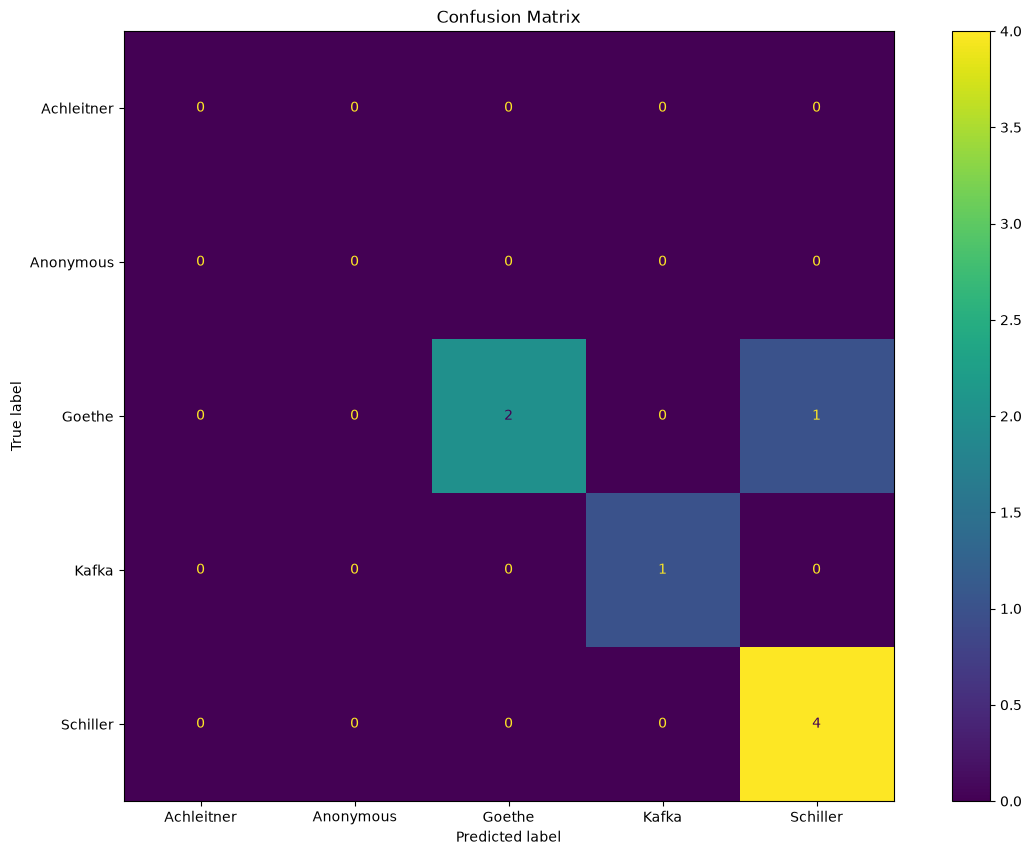

In [9]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(15, 10)
plt.title("Confusion Matrix")
plt.show()

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 87.50%


In [11]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Goethe       1.00      0.67      0.80         3
       Kafka       1.00      1.00      1.00         1
    Schiller       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.93      0.89      0.90         8
weighted avg       0.90      0.88      0.87         8



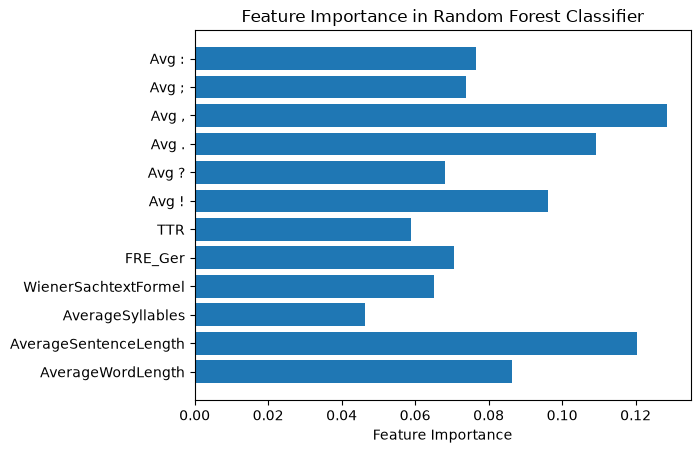

In [12]:
feature_importances = classifier.feature_importances_

plt.barh(X.columns, feature_importances)
plt.xlabel('Feature Importance')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

### 10 Fold Cross Valdidation

In [13]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.75       1.         0.25       0.5        0.
 0.33333333 1.         1.         1.        ]
Average CV Score:  0.6333333333333333
Number of CV Scores used in Average:  10


In [14]:
k_folds = KFold(n_splits = 20)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [1.  1.  0.5 1.  1.  1.  0.5 1.  0.5 1.  1.  0.  0.  1.  1.  1.  1.  1.
 1.  1. ]
Average CV Score:  0.825
Number of CV Scores used in Average:  20
